# 1) MLP: A * B % C (A,B between 0..99, C 0..19)

In [ ]:
#@title (0) Setup
from google.colab import drive
import sys
drive.mount('/content/drive')
#sys.path.append('/content/drive/MyDrive/Colab Notebooks')

%run "/content/drive/MyDrive/Colab Notebooks/Build your own LLM/han-common.ipynb"

Mounted at /content/drive
Train: 152,000 samples  |  Test: 38,000 samples
Input dim: 219  |  Output classes: 19
Label distribution (train): {np.int64(0): np.int64(51411), np.int64(1): np.int64(11977), np.int64(2): np.int64(14363), np.int64(3): np.int64(10413), np.int64(4): np.int64(11615), np.int64(5): np.int64(6717), np.int64(6): np.int64(10053), np.int64(7): np.int64(4823), np.int64(8): np.int64(6869), np.int64(9): np.int64(4650), np.int64(10): np.int64(4769), np.int64(11): np.int64(2542), np.int64(12): np.int64(4452), np.int64(13): np.int64(1747), np.int64(14): np.int64(2023), np.int64(15): np.int64(1374), np.int64(16): np.int64(1254), np.int64(17): np.int64(538), np.int64(18): np.int64(410)}
DNN(
  (proj_in): Linear(in_features=219, out_features=128, bias=True)
  (layers): ModuleList(
    (0-15): 16 x Sequential(
      (0): Linear(in_features=128, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=128, bias=True)
    )
  )
  (norms): Modu

## 1.3) Train


In [ ]:
def train(run_name="", norm_type=None, is_post_norm=False):
    model = DNN(layer_depth=72, norm_type=norm_type, is_post_norm=is_post_norm).to(DEVICE)
    return train_common(model, run_name)

# 2) Baseline: no normalization

In [ ]:
train(run_name="no normalization")

  🚀 Run: no normalization
Epoch      1 | Train loss 183251743035.6076  acc 13.0% | Test loss 183188086808.1448  acc 12.8%
Epoch      2 | Train loss 44529902687.2859  acc 23.5% | Test loss 44761275774.4370  acc 23.4%
Epoch      3 | Train loss 20624086294.0968  acc 21.3% | Test loss 20667203866.8396  acc 21.0%
Epoch      4 | Train loss 13230194173.6286  acc 12.3% | Test loss 13300944118.6223  acc 12.0%
Epoch      5 | Train loss 7896385840.3975  acc 15.5% | Test loss 7964876457.8762  acc 15.7%
Epoch      6 | Train loss 7178376564.9516  acc 7.6% | Test loss 7192584216.5760  acc 7.6%
Epoch      7 | Train loss 4941960367.4813  acc 9.7% | Test loss 4960109017.1958  acc 9.4%
Epoch      8 | Train loss 3530454617.4653  acc 13.9% | Test loss 3537922242.2366  acc 13.8%
Epoch      9 | Train loss 1788231544.1853  acc 15.7% | Test loss 1796701662.5853  acc 15.8%
Epoch     10 | Train loss 1908600333.0964  acc 22.8% | Test loss 1909595727.2253  acc 22.9%
Epoch     11 | Train loss 1488766768.6131  acc 1

# 3) Pre-norm RMSNorm

In [ ]:
train(run_name="pre-norm RMSNorm", norm_type=nn.RMSNorm)

  🚀 Run: pre-norm RMSNorm
Epoch      1 | Train loss 1.7430  acc 39.9% | Test loss 1.7765  acc 39.2%
Epoch      2 | Train loss 1.2890  acc 54.3% | Test loss 1.3307  acc 53.4%
Epoch      3 | Train loss 1.1687  acc 54.4% | Test loss 1.1997  acc 53.6%
Epoch      4 | Train loss 1.1024  acc 55.0% | Test loss 1.1287  acc 54.1%
Epoch      5 | Train loss 1.1245  acc 55.1% | Test loss 1.1457  acc 54.1%
Epoch      6 | Train loss 1.1341  acc 55.0% | Test loss 1.1547  acc 54.3%
Epoch      7 | Train loss 1.0991  acc 55.0% | Test loss 1.1233  acc 54.3%
Epoch      8 | Train loss 1.0612  acc 55.6% | Test loss 1.0824  acc 54.2%
Epoch      9 | Train loss 1.0607  acc 57.5% | Test loss 1.0801  acc 56.6%
Epoch     10 | Train loss 0.9236  acc 63.7% | Test loss 0.9429  acc 63.1%
Epoch     11 | Train loss 0.8833  acc 64.5% | Test loss 0.9008  acc 63.7%
Epoch     12 | Train loss 0.7491  acc 71.0% | Test loss 0.7611  acc 70.4%
Epoch     13 | Train loss 0.7447  acc 71.0% | Test loss 0.7529  acc 70.8%
Epoch     14

# 4) Post-norm RMSNorm

In [ ]:
train(run_name="post-norm RMSNorm", norm_type=nn.RMSNorm, is_post_norm=True)

  🚀 Run: post-norm RMSNorm
Epoch      1 | Train loss 2.3611  acc 33.8% | Test loss 2.3676  acc 33.6%
Epoch      2 | Train loss 2.3565  acc 33.8% | Test loss 2.3620  acc 33.6%
Epoch      3 | Train loss 2.3582  acc 33.8% | Test loss 2.3647  acc 33.6%
Epoch      4 | Train loss 2.3576  acc 33.8% | Test loss 2.3630  acc 33.6%
Epoch      5 | Train loss 2.3559  acc 33.8% | Test loss 2.3610  acc 33.6%
Epoch      6 | Train loss 2.3546  acc 33.8% | Test loss 2.3607  acc 33.6%
Epoch      7 | Train loss 2.3555  acc 33.8% | Test loss 2.3614  acc 33.6%
Epoch      8 | Train loss 2.3553  acc 33.8% | Test loss 2.3611  acc 33.6%
Epoch      9 | Train loss 2.3540  acc 33.8% | Test loss 2.3593  acc 33.6%
Epoch     10 | Train loss 2.3553  acc 33.8% | Test loss 2.3599  acc 33.6%
Epoch     11 | Train loss 2.3536  acc 33.8% | Test loss 2.3587  acc 33.6%
Epoch     12 | Train loss 2.3560  acc 33.8% | Test loss 2.3616  acc 33.6%
Epoch     13 | Train loss 2.3545  acc 33.8% | Test loss 2.3609  acc 33.6%
Epoch     1

# 5) Pre-norm LayerNorm

In [ ]:
train(run_name="pre-norm LayerNorm", norm_type=nn.LayerNorm)

  🚀 Run: pre-norm LayerNorm


W1020 20:06:46.870000 709 torch/_dynamo/convert_frame.py:1743] [0/8] torch._dynamo hit config.recompile_limit (8)
W1020 20:06:46.870000 709 torch/_dynamo/convert_frame.py:1743] [0/8]    function: 'forward' (/tmp/ipykernel_709/3472143706.py:22)
W1020 20:06:46.870000 709 torch/_dynamo/convert_frame.py:1743] [0/8]    last reason: 0/7: GLOBAL_STATE changed: grad_mode 
W1020 20:06:46.870000 709 torch/_dynamo/convert_frame.py:1743] [0/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1020 20:06:46.870000 709 torch/_dynamo/convert_frame.py:1743] [0/8] To diagnose recompilation issues, see https://docs.pytorch.org/docs/main/user_guide/torch_compiler/compile/programming_model.recompilation.html


Epoch      1 | Train loss 1.6516  acc 45.2% | Test loss 1.7020  acc 43.9%
Epoch      2 | Train loss 1.3061  acc 54.6% | Test loss 1.3514  acc 53.6%
Epoch      3 | Train loss 1.1926  acc 55.1% | Test loss 1.2286  acc 53.9%
Epoch      4 | Train loss 1.1194  acc 54.6% | Test loss 1.1546  acc 53.5%
Epoch      5 | Train loss 1.1532  acc 55.1% | Test loss 1.1871  acc 54.0%
Epoch      6 | Train loss 1.1264  acc 55.3% | Test loss 1.1549  acc 54.1%
Epoch      7 | Train loss 1.0910  acc 56.2% | Test loss 1.1206  acc 55.0%
Epoch      8 | Train loss 1.0052  acc 59.3% | Test loss 1.0304  acc 58.1%
Epoch      9 | Train loss 0.9246  acc 63.9% | Test loss 0.9318  acc 63.5%
Epoch     10 | Train loss 0.9065  acc 64.8% | Test loss 0.9225  acc 64.0%
Epoch     11 | Train loss 0.8431  acc 65.7% | Test loss 0.8606  acc 65.2%
Epoch     12 | Train loss 0.8131  acc 66.6% | Test loss 0.8308  acc 65.6%
Epoch     13 | Train loss 0.7055  acc 72.2% | Test loss 0.7154  acc 71.6%
Epoch     14 | Train loss 0.7113  acc 

# 6) Post-norm LayerNorm

In [ ]:
train(run_name="post-norm LayerNorm", norm_type=nn.LayerNorm, is_post_norm=True)

  🚀 Run: post-norm LayerNorm
Epoch      1 | Train loss 2.3611  acc 33.8% | Test loss 2.3676  acc 33.6%
Epoch      2 | Train loss 2.3567  acc 33.8% | Test loss 2.3621  acc 33.6%
Epoch      3 | Train loss 2.3592  acc 33.8% | Test loss 2.3656  acc 33.6%
Epoch      4 | Train loss 2.3580  acc 33.8% | Test loss 2.3634  acc 33.6%
Epoch      5 | Train loss 2.3561  acc 33.8% | Test loss 2.3612  acc 33.6%
Epoch      6 | Train loss 2.3549  acc 33.8% | Test loss 2.3611  acc 33.6%
Epoch      7 | Train loss 2.3556  acc 33.8% | Test loss 2.3616  acc 33.6%
Epoch      8 | Train loss 2.3561  acc 33.8% | Test loss 2.3621  acc 33.6%
Epoch      9 | Train loss 2.3540  acc 33.8% | Test loss 2.3592  acc 33.6%
Epoch     10 | Train loss 2.3556  acc 33.8% | Test loss 2.3602  acc 33.6%
Epoch     11 | Train loss 2.3537  acc 33.8% | Test loss 2.3588  acc 33.6%
Epoch     12 | Train loss 2.3557  acc 33.8% | Test loss 2.3614  acc 33.6%
Epoch     13 | Train loss 2.3545  acc 33.8% | Test loss 2.3610  acc 33.6%
Epoch    

# 7) Pre-norm BatchNorm

In [ ]:
train(run_name="pre-norm BatchNorm", norm_type=nn.BatchNorm1d)

  🚀 Run: pre-norm BatchNorm
Epoch      1 | Train loss 1.0748  acc 54.7% | Test loss 1.0872  acc 54.1%
Epoch      2 | Train loss 1.0040  acc 57.9% | Test loss 1.0138  acc 57.2%
Epoch      3 | Train loss 0.9483  acc 60.9% | Test loss 0.9595  acc 60.2%
Epoch      4 | Train loss 0.8579  acc 65.2% | Test loss 0.8617  acc 65.2%
Epoch      5 | Train loss 0.8466  acc 65.6% | Test loss 0.8514  acc 65.3%
Epoch      6 | Train loss 0.8388  acc 65.7% | Test loss 0.8427  acc 65.5%
Epoch      7 | Train loss 0.8428  acc 65.7% | Test loss 0.8496  acc 65.4%
Epoch      8 | Train loss 0.8308  acc 66.0% | Test loss 0.8347  acc 65.3%
Epoch      9 | Train loss 0.8282  acc 65.8% | Test loss 0.8318  acc 65.9%
Epoch     10 | Train loss 0.8365  acc 66.1% | Test loss 0.8463  acc 65.6%
Epoch     11 | Train loss 0.8182  acc 66.4% | Test loss 0.8240  acc 66.1%
Epoch     12 | Train loss 0.7929  acc 68.2% | Test loss 0.7971  acc 68.0%
Epoch     13 | Train loss 0.7069  acc 72.9% | Test loss 0.7100  acc 72.8%
Epoch     

OptimizedModule(
  (_orig_mod): DNN(
    (proj_in): Linear(in_features=219, out_features=128, bias=True)
    (layers): ModuleList(
      (0-71): 72 x Sequential(
        (0): Linear(in_features=128, out_features=256, bias=True)
        (1): ReLU()
        (2): Linear(in_features=256, out_features=128, bias=True)
      )
    )
    (norms): ModuleList(
      (0-71): 72 x BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (dropouts): ModuleList(
      (0-71): 72 x Dropout(p=0.0, inplace=False)
    )
    (proj_out): Linear(in_features=128, out_features=19, bias=True)
  )
)

# 8) Post-norm BatchNorm

In [ ]:
train(run_name="post-norm BatchNorm", norm_type=nn.BatchNorm1d, is_post_norm=True)

# 9) Loss + Accuracy across runs

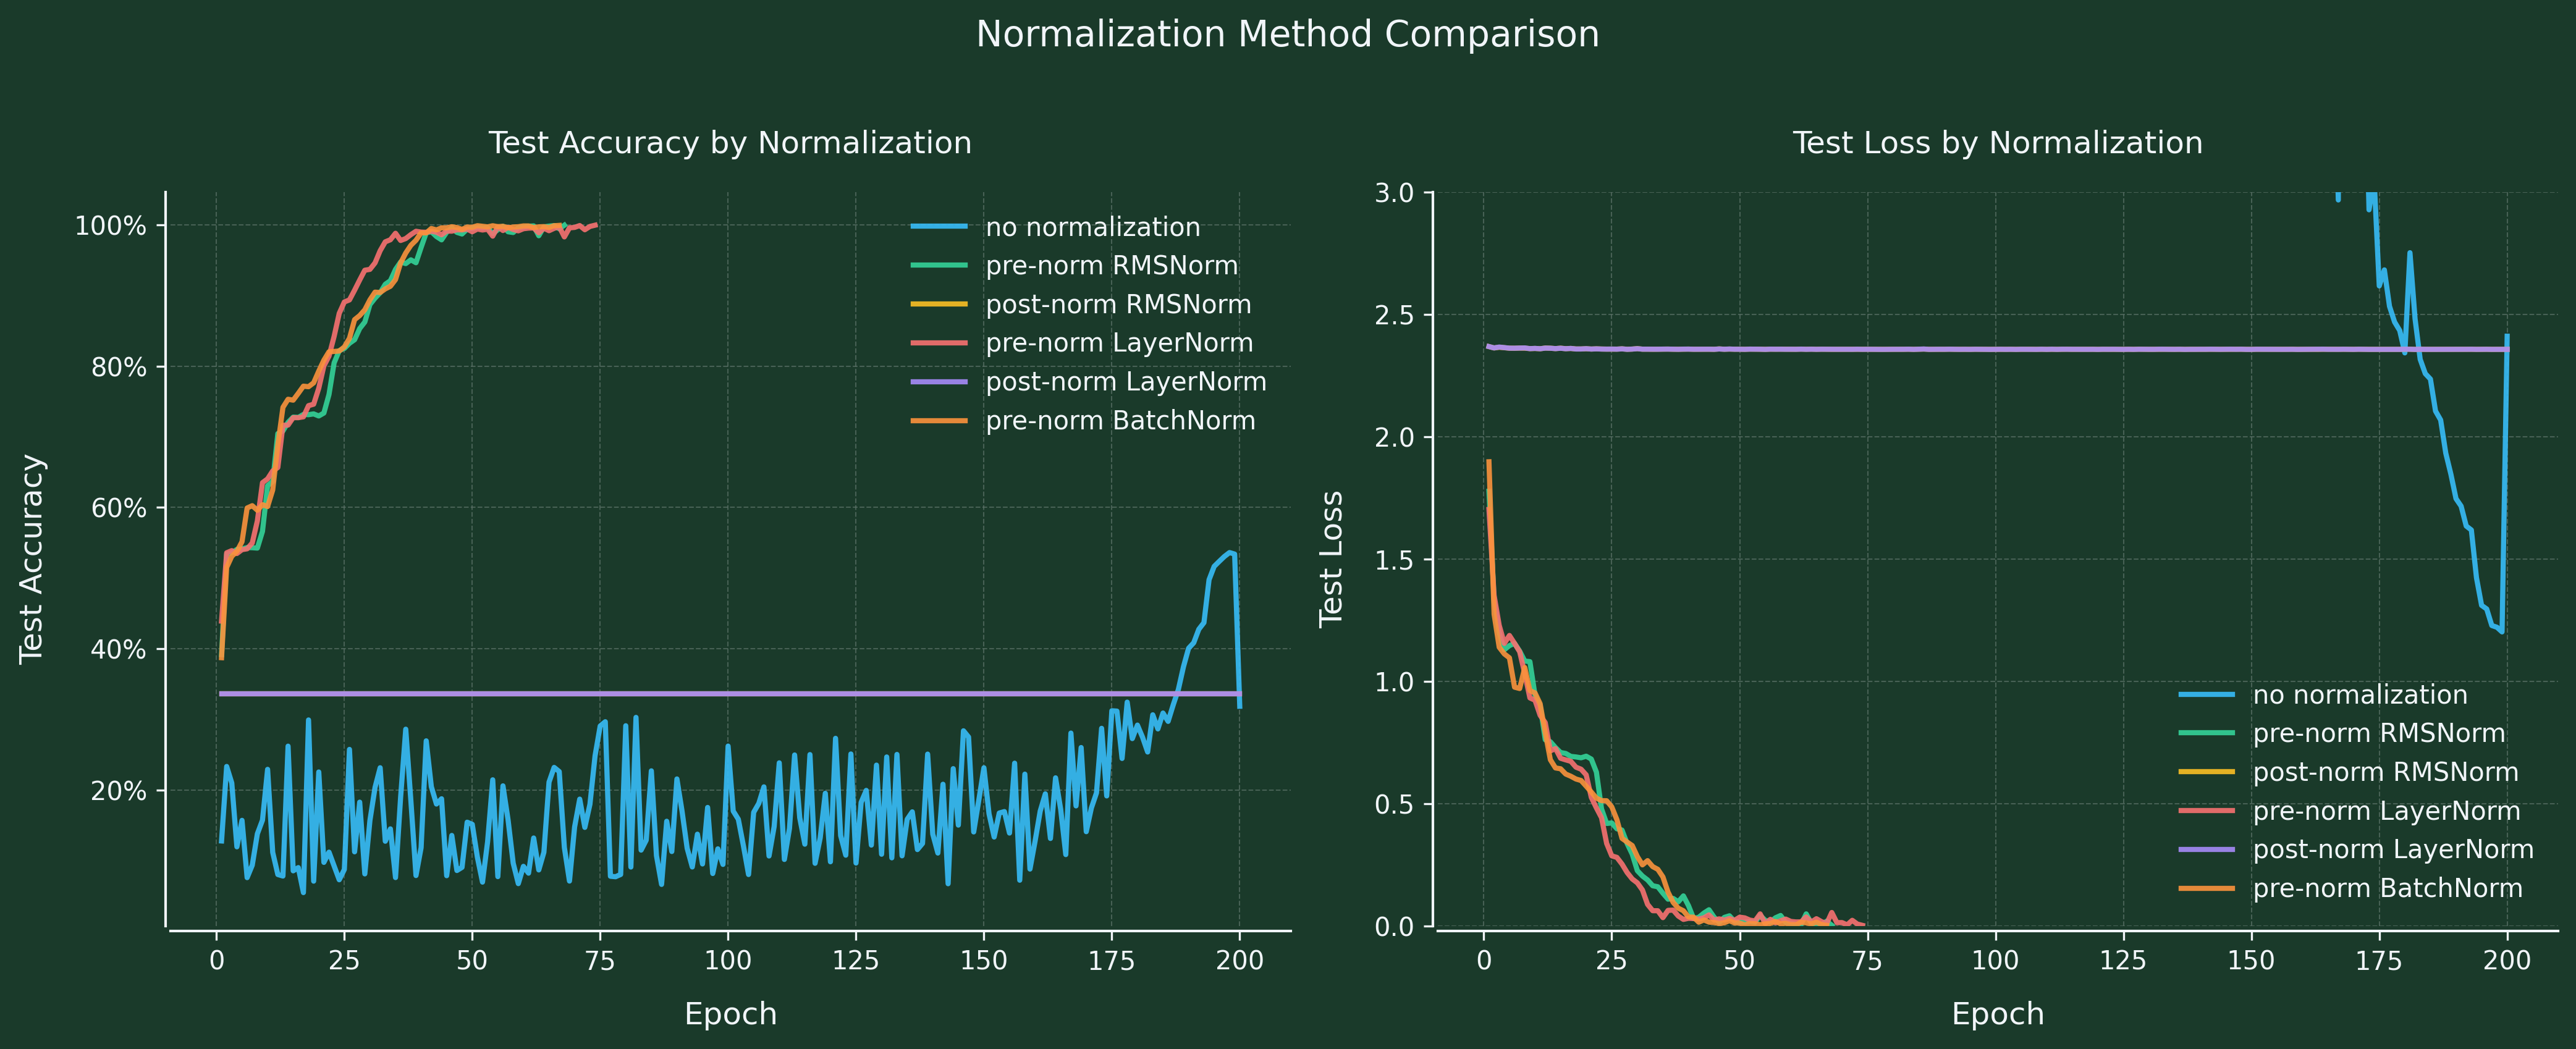


Run                  Converged Epoch     
----------------------------------------
pre-norm BatchNorm   67                  
pre-norm RMSNorm     68                  
pre-norm LayerNorm   74                  
no normalization     Did not converge    
post-norm RMSNorm    Did not converge    
post-norm LayerNorm  Did not converge    


In [ ]:
#@title Visualize
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import matplotlib.colors as mcolors
import logging
import matplotlib.ticker as ticker

# Suppress missing font warnings
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# Prefer the deployment font when available, otherwise fall back to common sans-serif fonts
font_candidates = ['Inter', 'DejaVu Sans', 'Arial', 'Helvetica', 'sans-serif']
plt.rcParams['font.family'] = font_candidates
font_path = 'fonts/Inter-Regular.ttf'
try:
    prop = fm.FontProperties(fname=font_path)
    plt.rcParams['font.family'] = prop.get_name()
except Exception:
    pass

# Set styling for all text and lines
plt.rcParams['text.color'] = '#F1F5F9'
plt.rcParams['axes.labelcolor'] = '#F1F5F9'
plt.rcParams['xtick.color'] = '#F1F5F9'
plt.rcParams['ytick.color'] = '#F1F5F9'
plt.rcParams['axes.edgecolor'] = '#F1F5F9'

# Grid styling
plt.rcParams['grid.color'] = '#5B7268'
plt.rcParams['grid.alpha'] = 0.7

def _coplot_luminance_from_rgba(rgba):
    r, g, b = mcolors.to_rgb(rgba)
    def _linear(c):
        return c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4
    return 0.2126 * _linear(r) + 0.7152 * _linear(g) + 0.0722 * _linear(b)

def _coplot_text_color_for_rgba(rgba, preferred='#F1F5F9'):
    try:
        preferred_l = _coplot_luminance_from_rgba(mcolors.to_rgba(preferred))
        bg_l = _coplot_luminance_from_rgba(rgba)
        lighter = max(preferred_l, bg_l)
        darker = min(preferred_l, bg_l)
        ratio = (lighter + 0.05) / (darker + 0.05)
        if ratio >= 4.5:
            return preferred
    except Exception:
        pass
    bg_l = _coplot_luminance_from_rgba(rgba)
    return '#111111' if bg_l > 0.5 else '#FFFFFF'

# Create figure and axis with publication-quality settings
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)
fig.patch.set_facecolor('#1A3A2A')

# Distinct bright colors for dark background (modified to keep runs distinguishable)
colors = ["#38BDF8", "#34D399", "#FBBF24", "#F87171", "#A78BFA", "#FB923C", "#E879F9"]
line_styles = ["-","--",":","-."]
marker_styles = ["o","s","^","D"]

for idx, run in enumerate(all_runs):
    h = run["history"]

    line_style = line_styles[idx % len(line_styles)] if False else '-'
    marker_style = marker_styles[idx % len(marker_styles)] if False else ''

    # Plot accuracy
    axes[0].plot(h["epoch"], h["test_acc"], label=run["name"],
                 color=colors[idx % len(colors)], linewidth=2,
                 linestyle=line_style, marker=marker_style, alpha=0.9)

    # Plot loss
    axes[1].plot(h["epoch"], h["test_loss"], label=run["name"],
                 color=colors[idx % len(colors)], linewidth=2,
                 linestyle=line_style, marker=marker_style, alpha=0.9)

# Apply custom styling to both axes
for ax in axes:
    ax.set_facecolor('#1A3A2A')
    ax.set_xlabel('Epoch', fontsize=12, labelpad=10, color='#F1F5F9')

    # Force integer epochs
    ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

    # Add grid
    ax.grid(axis='both', alpha=0.7, color='#5B7268', linestyle='--', linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    # Remove top and right spines for cleaner look
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1)
    ax.spines['left'].set_linewidth(1)
    ax.spines['bottom'].set_color('#F1F5F9')
    ax.spines['left'].set_color('#F1F5F9')

    # Adjust spine positions
    ax.spines['left'].set_position(('outward', 2))
    ax.spines['bottom'].set_position(('outward', 2))

    # Add legend
    ax.legend(frameon=False, fontsize=10)

# Specific titles and labels
axes[0].set_ylabel('Test Accuracy', fontsize=12, color='#F1F5F9', labelpad=10)
axes[0].set_title('Test Accuracy by Normalization', color='#F1F5F9', pad=15)
axes[0].yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

axes[1].set_ylabel('Test Loss', fontsize=12, color='#F1F5F9', labelpad=10)
axes[1].set_title('Test Loss by Normalization', color='#F1F5F9', pad=15)
axes[1].set_yscale('linear')
axes[1].set_ylim(top=3.0)
axes[1].set_ylim(bottom=0.0)
axes[1].yaxis.set_major_formatter(ticker.ScalarFormatter())

# Global title
plt.suptitle("Normalization Method Comparison", fontsize=14, y=1.02, color='#F1F5F9')

# Tight layout
plt.tight_layout()
plt.show()

# Summary table
print(f"\n{'Run':<20s} {'Converged Epoch':<20s}")
print("-" * 40)
for run in sorted(all_runs, key=lambda x: (x['converged_epoch'] is None, x['converged_epoch'])):
    ep = run["converged_epoch"]
    print(f"{run['name']:<20s} {str(ep) if ep else 'Did not converge':<20s}")

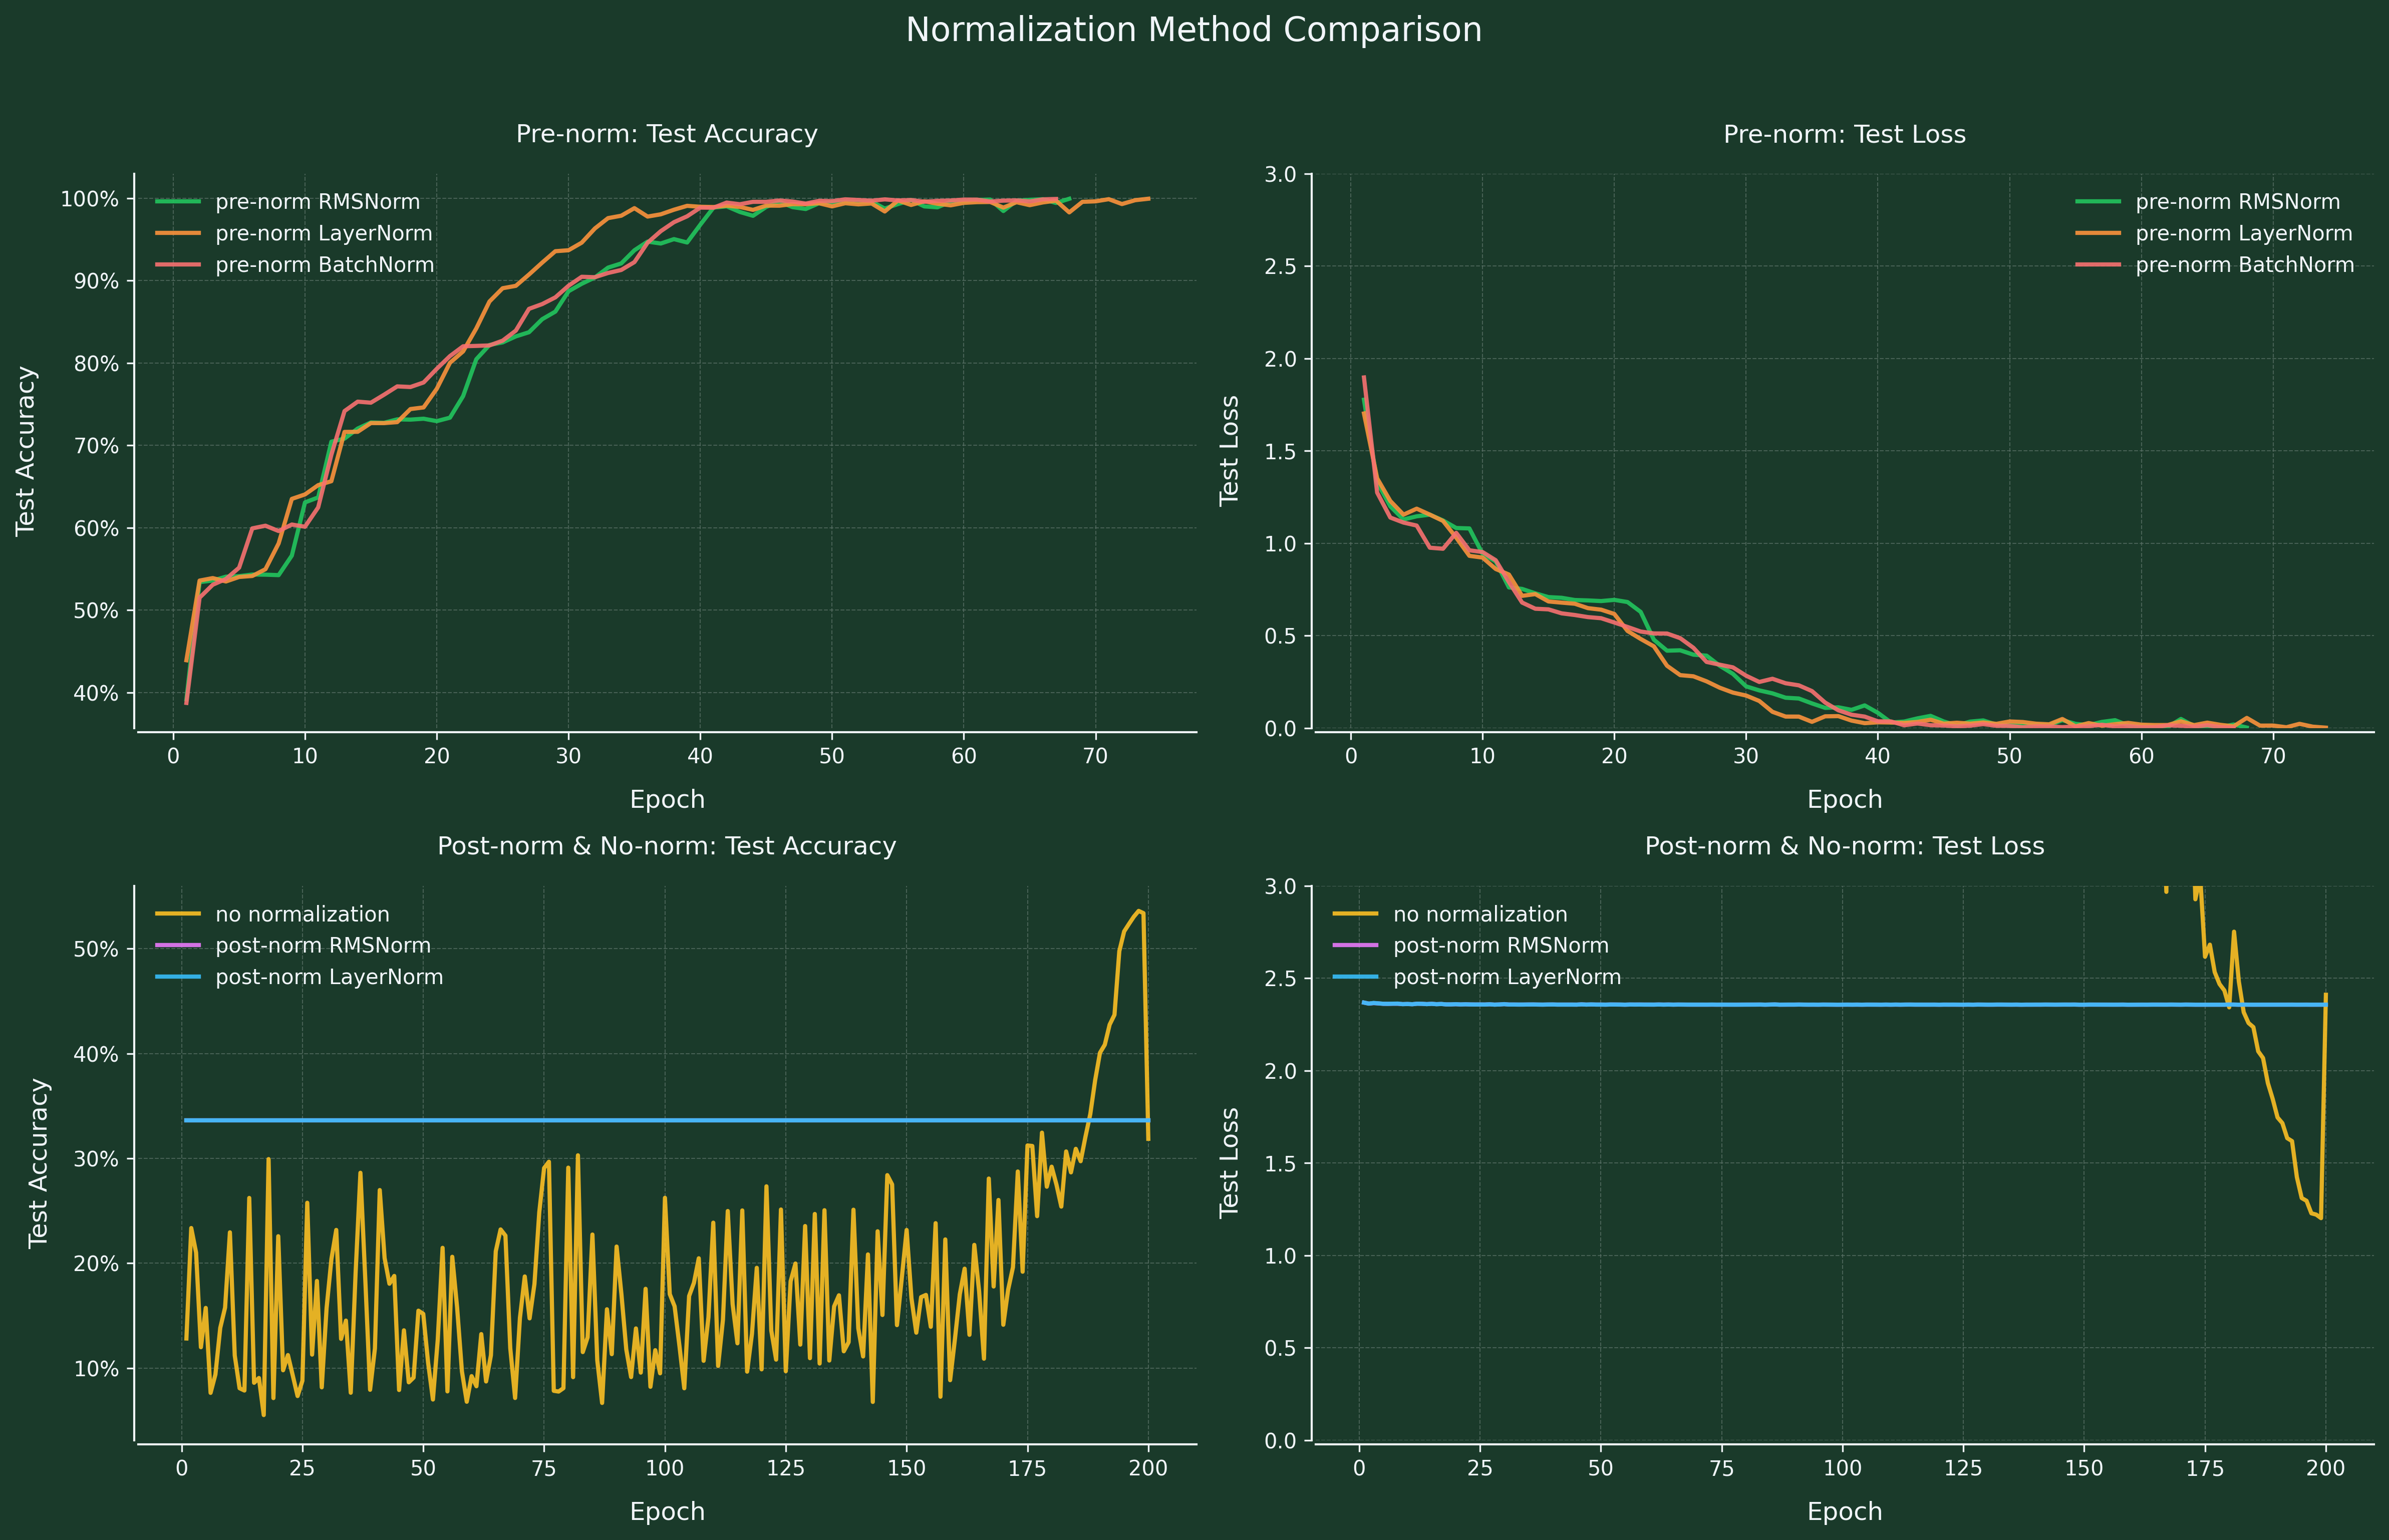

In [ ]:
#@title Visualize 2x2 Accuracy & Loss
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import matplotlib.colors as mcolors
import logging
import matplotlib.ticker as ticker

# Suppress missing font warnings
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# Prefer the deployment font when available, otherwise fall back to common sans-serif fonts
font_candidates = ['Inter', 'DejaVu Sans', 'Arial', 'Helvetica', 'sans-serif']
plt.rcParams['font.family'] = font_candidates
font_path = 'fonts/Inter-Regular.ttf'
try:
    prop = fm.FontProperties(fname=font_path)
    plt.rcParams['font.family'] = prop.get_name()
except Exception:
    pass

# Set styling for all text and lines
plt.rcParams['text.color'] = '#F1F5F9'
plt.rcParams['axes.labelcolor'] = '#F1F5F9'
plt.rcParams['xtick.color'] = '#F1F5F9'
plt.rcParams['ytick.color'] = '#F1F5F9'
plt.rcParams['axes.edgecolor'] = '#F1F5F9'

# Grid styling
plt.rcParams['grid.color'] = '#5B7268'
plt.rcParams['grid.alpha'] = 0.7

# Create figure and axis with publication-quality settings
fig, axes = plt.subplots(2, 2, figsize=(16, 10), dpi=300)
fig.patch.set_facecolor('#1A3A2A')

run_color_map = {
    "pre-norm BatchNorm": "#F87171", # Red hue
    "pre-norm LayerNorm": "#FB923C", # Orange hue
    "pre-norm RMSNorm": "#22C55E",   # Green hue
    "post-norm BatchNorm": "#A78BFA",# Purple hue
    "post-norm LayerNorm": "#38BDF8",# Blue hue
    "post-norm RMSNorm": "#E879F9",  # Pink hue
    "no normalization": "#FBBF24"    # Yellow hue
}
fallback_colors = ["#38BDF8", "#34D399", "#FBBF24", "#F87171", "#A78BFA", "#FB923C", "#E879F9"]

for idx, run in enumerate(all_runs):
    h = run["history"]

    is_pre = "pre-norm" in run["name"]
    row_idx = 0 if is_pre else 1

    run_color = run_color_map.get(run["name"], fallback_colors[idx % len(fallback_colors)])

    # Plot accuracy
    axes[row_idx, 0].plot(h["epoch"], h["test_acc"], label=run["name"],
                 color=run_color, linewidth=2, alpha=0.9)

    # Plot loss
    axes[row_idx, 1].plot(h["epoch"], h["test_loss"], label=run["name"],
                 color=run_color, linewidth=2, alpha=0.9)

# Apply custom styling to all axes
for r in range(2):
    for c in range(2):
        ax = axes[r, c]
        ax.set_facecolor('#1A3A2A')
        ax.set_xlabel('Epoch', fontsize=12, labelpad=10, color='#F1F5F9')

        # Force integer epochs
        ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

        # Add grid
        ax.grid(axis='both', alpha=0.7, color='#5B7268', linestyle='--', linewidth=0.5, zorder=0)
        ax.set_axisbelow(True)

        # Remove top and right spines for cleaner look
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_linewidth(1)
        ax.spines['left'].set_linewidth(1)
        ax.spines['bottom'].set_color('#F1F5F9')
        ax.spines['left'].set_color('#F1F5F9')

        # Adjust spine positions
        ax.spines['left'].set_position(('outward', 2))
        ax.spines['bottom'].set_position(('outward', 2))

        # Add legend
        ax.legend(frameon=False, fontsize=10)

# Specific titles and labels
axes[0, 0].set_ylabel('Test Accuracy', fontsize=12, color='#F1F5F9', labelpad=10)
axes[0, 0].set_title('Pre-norm: Test Accuracy', color='#F1F5F9', pad=15)
axes[0, 0].yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

axes[0, 1].set_ylabel('Test Loss', fontsize=12, color='#F1F5F9', labelpad=10)
axes[0, 1].set_title('Pre-norm: Test Loss', color='#F1F5F9', pad=15)
axes[0, 1].set_yscale('linear')
axes[0, 1].set_ylim(bottom=0.0, top=3.0)

axes[1, 0].set_ylabel('Test Accuracy', fontsize=12, color='#F1F5F9', labelpad=10)
axes[1, 0].set_title('Post-norm & No-norm: Test Accuracy', color='#F1F5F9', pad=15)
axes[1, 0].yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

axes[1, 1].set_ylabel('Test Loss', fontsize=12, color='#F1F5F9', labelpad=10)
axes[1, 1].set_title('Post-norm & No-norm: Test Loss', color='#F1F5F9', pad=15)
axes[1, 1].set_yscale('linear')
axes[1, 1].set_ylim(bottom=0.0, top=3.0)

# Global title
plt.suptitle("Normalization Method Comparison", fontsize=16, y=1.02, color='#F1F5F9')

# Tight layout
plt.tight_layout()
plt.show()

# 10) Activation values visualized

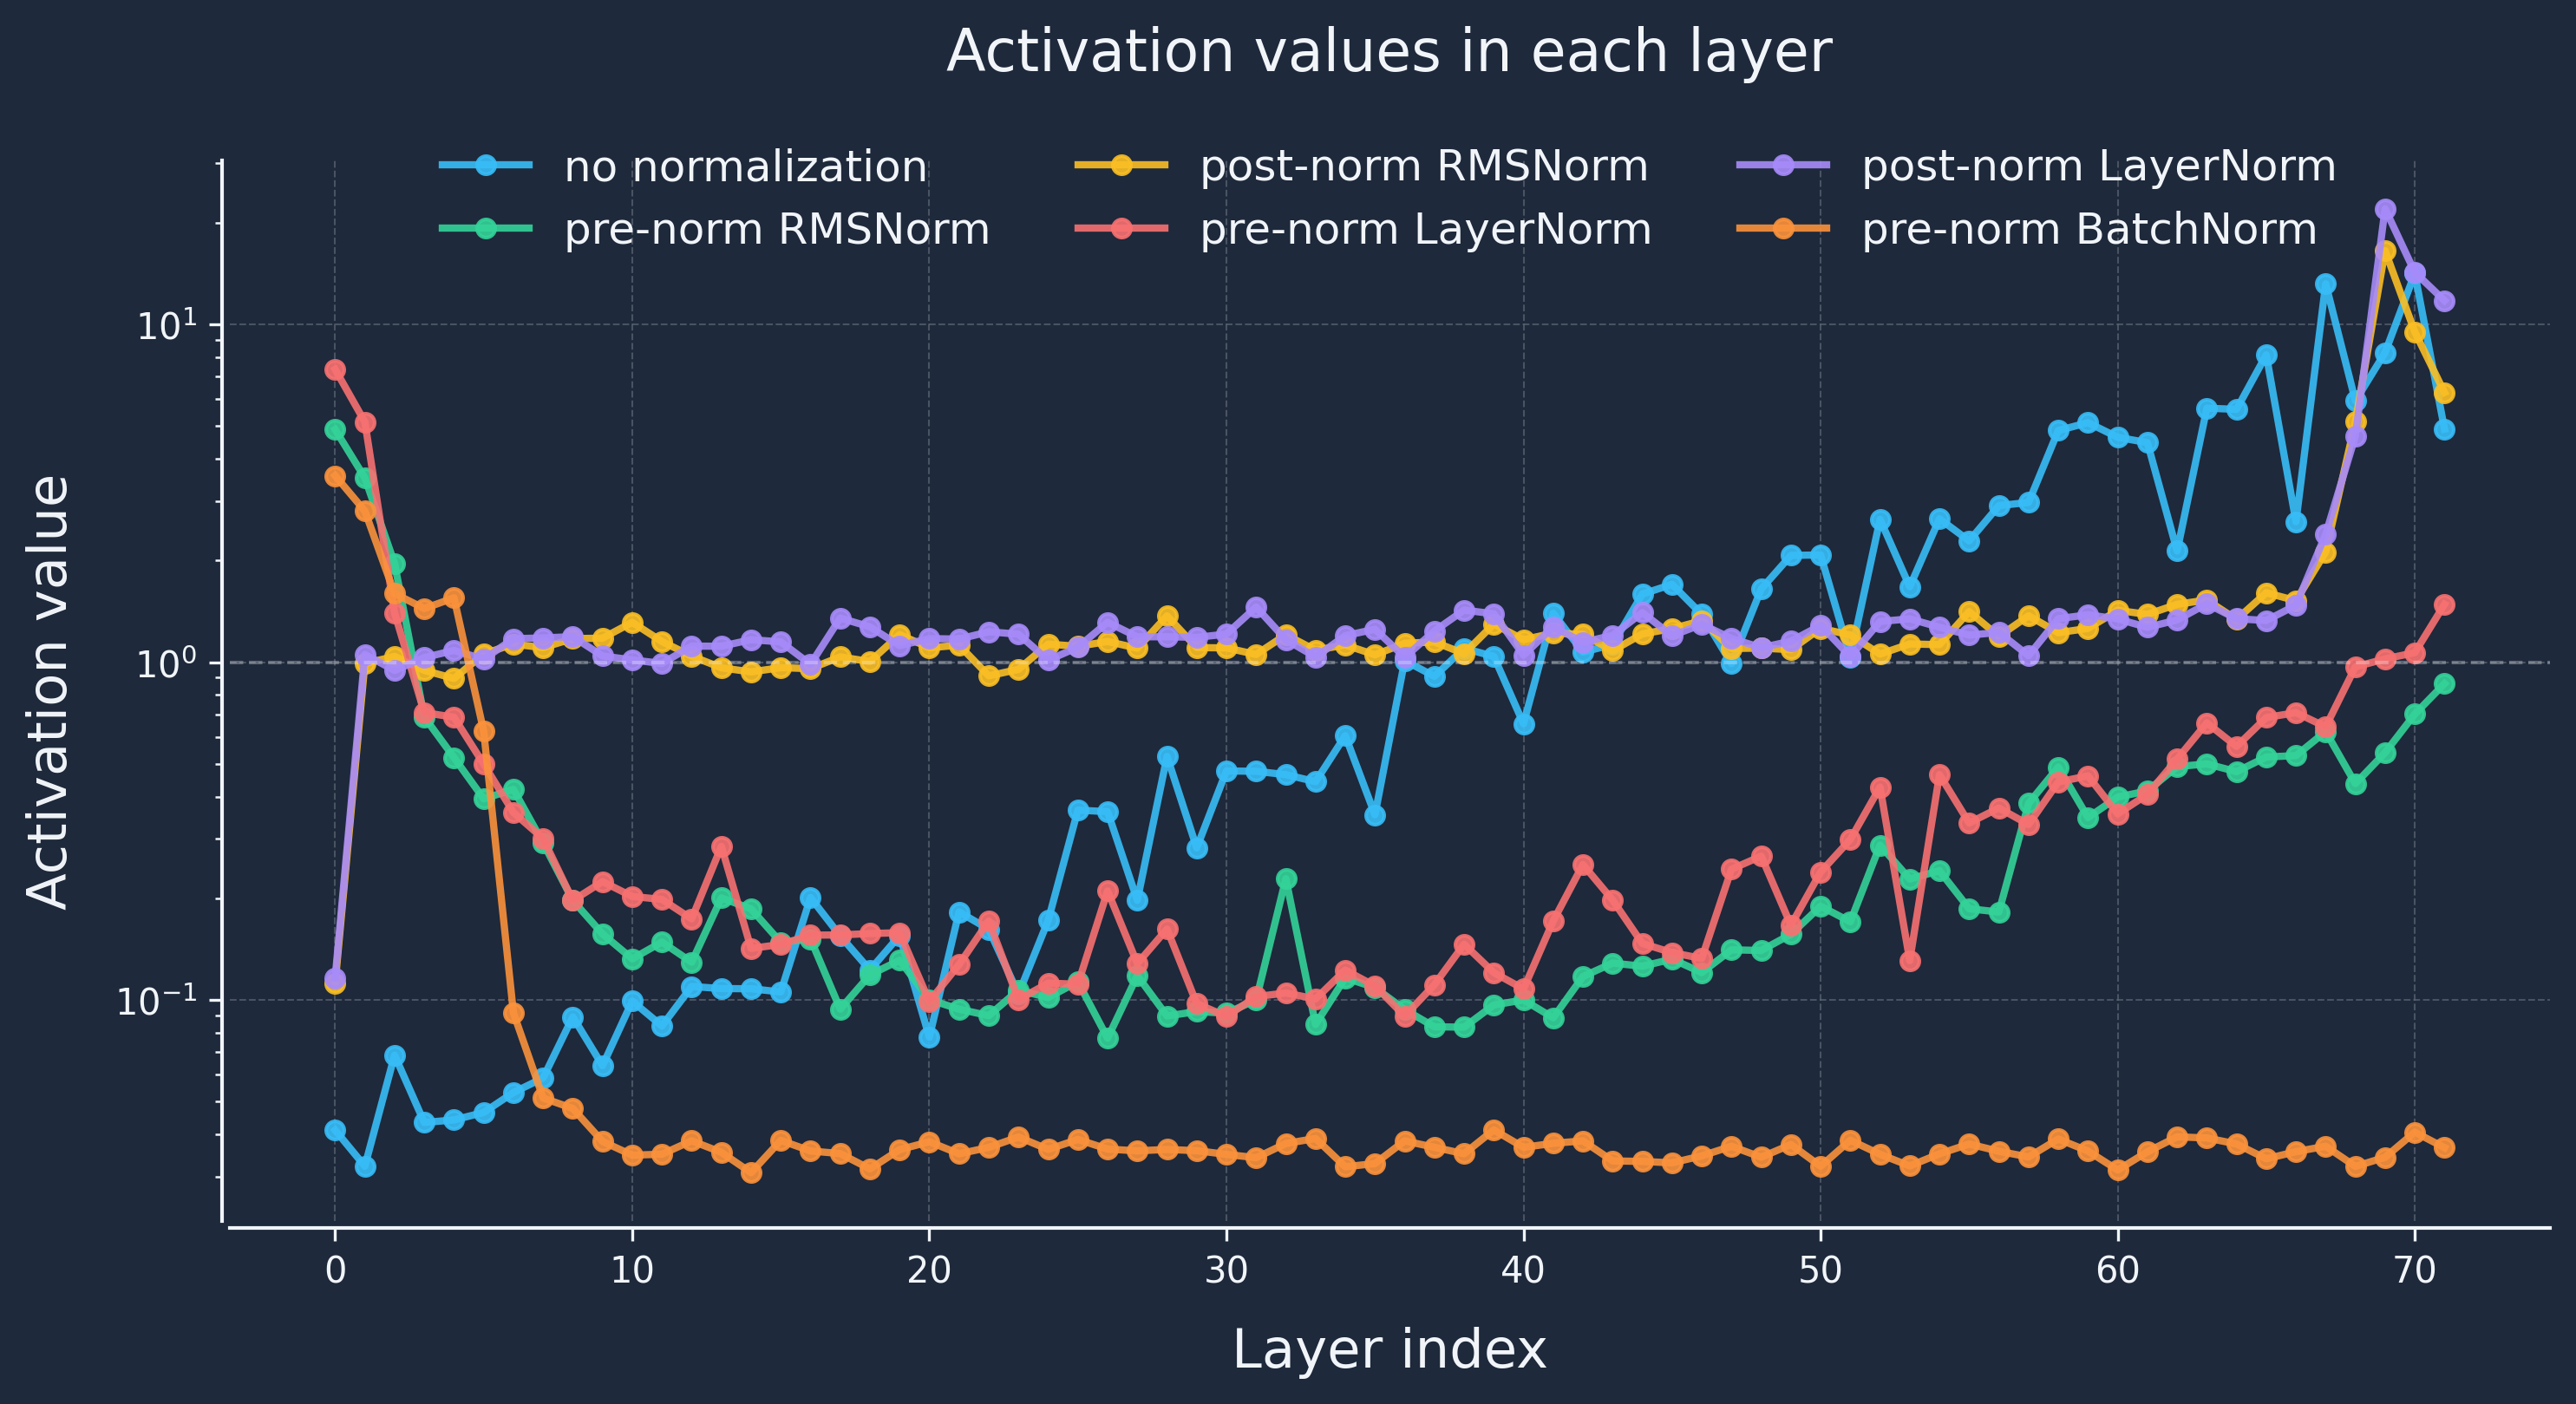

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import matplotlib.colors as mcolors
import torch

# Prefer the deployment font when available, otherwise fall back to common sans-serif fonts
font_candidates = ['Inter', 'DejaVu Sans', 'Arial', 'Helvetica', 'sans-serif']
plt.rcParams['font.family'] = font_candidates
font_path = 'fonts/Inter-Regular.ttf'
try:
    prop = fm.FontProperties(fname=font_path)
    plt.rcParams['font.family'] = prop.get_name()
except Exception:
    pass

# Set styling for all text and lines
plt.rcParams['text.color'] = '#F1F5F9'
plt.rcParams['axes.labelcolor'] = '#F1F5F9'
plt.rcParams['xtick.color'] = '#F1F5F9'
plt.rcParams['ytick.color'] = '#F1F5F9'
plt.rcParams['axes.edgecolor'] = '#F1F5F9'

# Grid styling
plt.rcParams['grid.color'] = '#5D6674'
plt.rcParams['grid.alpha'] = 0.7

def _coplot_luminance_from_rgba(rgba):
    r, g, b = mcolors.to_rgb(rgba)
    def _linear(c):
        return c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4
    return 0.2126 * _linear(r) + 0.7152 * _linear(g) + 0.0722 * _linear(b)

def _coplot_text_color_for_rgba(rgba, preferred='#F1F5F9'):
    try:
        preferred_l = _coplot_luminance_from_rgba(mcolors.to_rgba(preferred))
        bg_l = _coplot_luminance_from_rgba(rgba)
        lighter = max(preferred_l, bg_l)
        darker = min(preferred_l, bg_l)
        ratio = (lighter + 0.05) / (darker + 0.05)
        if ratio >= 4.5:
            return preferred
    except Exception:
        pass
    bg_l = _coplot_luminance_from_rgba(rgba)
    return '#111111' if bg_l > 0.5 else '#FFFFFF'

# ── Signal survival per layer (post-hoc) ──
xb, yb = next(iter(test_loader))

# Create figure and axis with publication-quality settings
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
fig.patch.set_facecolor('#1E293B')
ax.set_facecolor('#1E293B')

# Define distinct bright colors instead of the same blue, so lines are distinguishable
colors = ["#38BDF8", "#34D399", "#FBBF24", "#F87171", "#A78BFA", "#FB923C", "#E879F9"]
line_styles = ["-","--",":","-."]
marker_styles = ["o","s","^","D"]

for idx, run in enumerate(all_runs):
    model = run["model"].eval()
    if hasattr(model, "_orig_mod"):
        model = model._orig_mod

    magnitudes = []

    handles = []
    def make_hook(store):
        def hook(module, input, output):
            store.append(output.detach().abs().mean().item())
        return hook

    for block in model.layers:
        m = []
        magnitudes.append(m)
        handles.append(block.register_forward_hook(make_hook(m)))

    with torch.no_grad():
        model(xb)

    for h in handles:
        h.remove()

    layer_means = [m[0] for m in magnitudes]

    line_style = line_styles[idx % len(line_styles)] if False else '-'
    marker_style = marker_styles[idx % len(marker_styles)] if False else 'o'

    ax.plot(range(len(layer_means)), layer_means,
           color=colors[idx % len(colors)],
           linewidth=2,
           linestyle=line_style,
           marker=marker_style, markersize=5,
           label=run["name"],
           alpha=0.9)

ax.set_yscale("log")
ax.axhline(y=1.0, color="#F1F5F9", linestyle="--", alpha=0.3, linewidth=1)

# Customize axis labels
ax.set_xlabel('Layer index', fontsize=15, labelpad=10, color='#F1F5F9')
ax.set_ylabel('Activation value', fontsize=15, color='#F1F5F9', labelpad=10)
ax.set_title("Activation values in each layer", fontsize=16, color='#F1F5F9', pad=25)

# Add grid
ax.grid(axis='both', alpha=0.7, color='#5D6674', linestyle='--', linewidth=0.5, zorder=0)
ax.set_axisbelow(True)

# Add legend
ax.legend(loc='upper center',
         bbox_to_anchor=(0.5, 1.05),
         frameon=False, fontsize=12, ncol=3)

# Remove top and right spines for cleaner look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1)
ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_color('#F1F5F9')
ax.spines['left'].set_color('#F1F5F9')

# Adjust spine positions
ax.spines['left'].set_position(('outward', 2))
ax.spines['bottom'].set_position(('outward', 2))

# Tight layout
plt.tight_layout()

# Display the plot
plt.show()

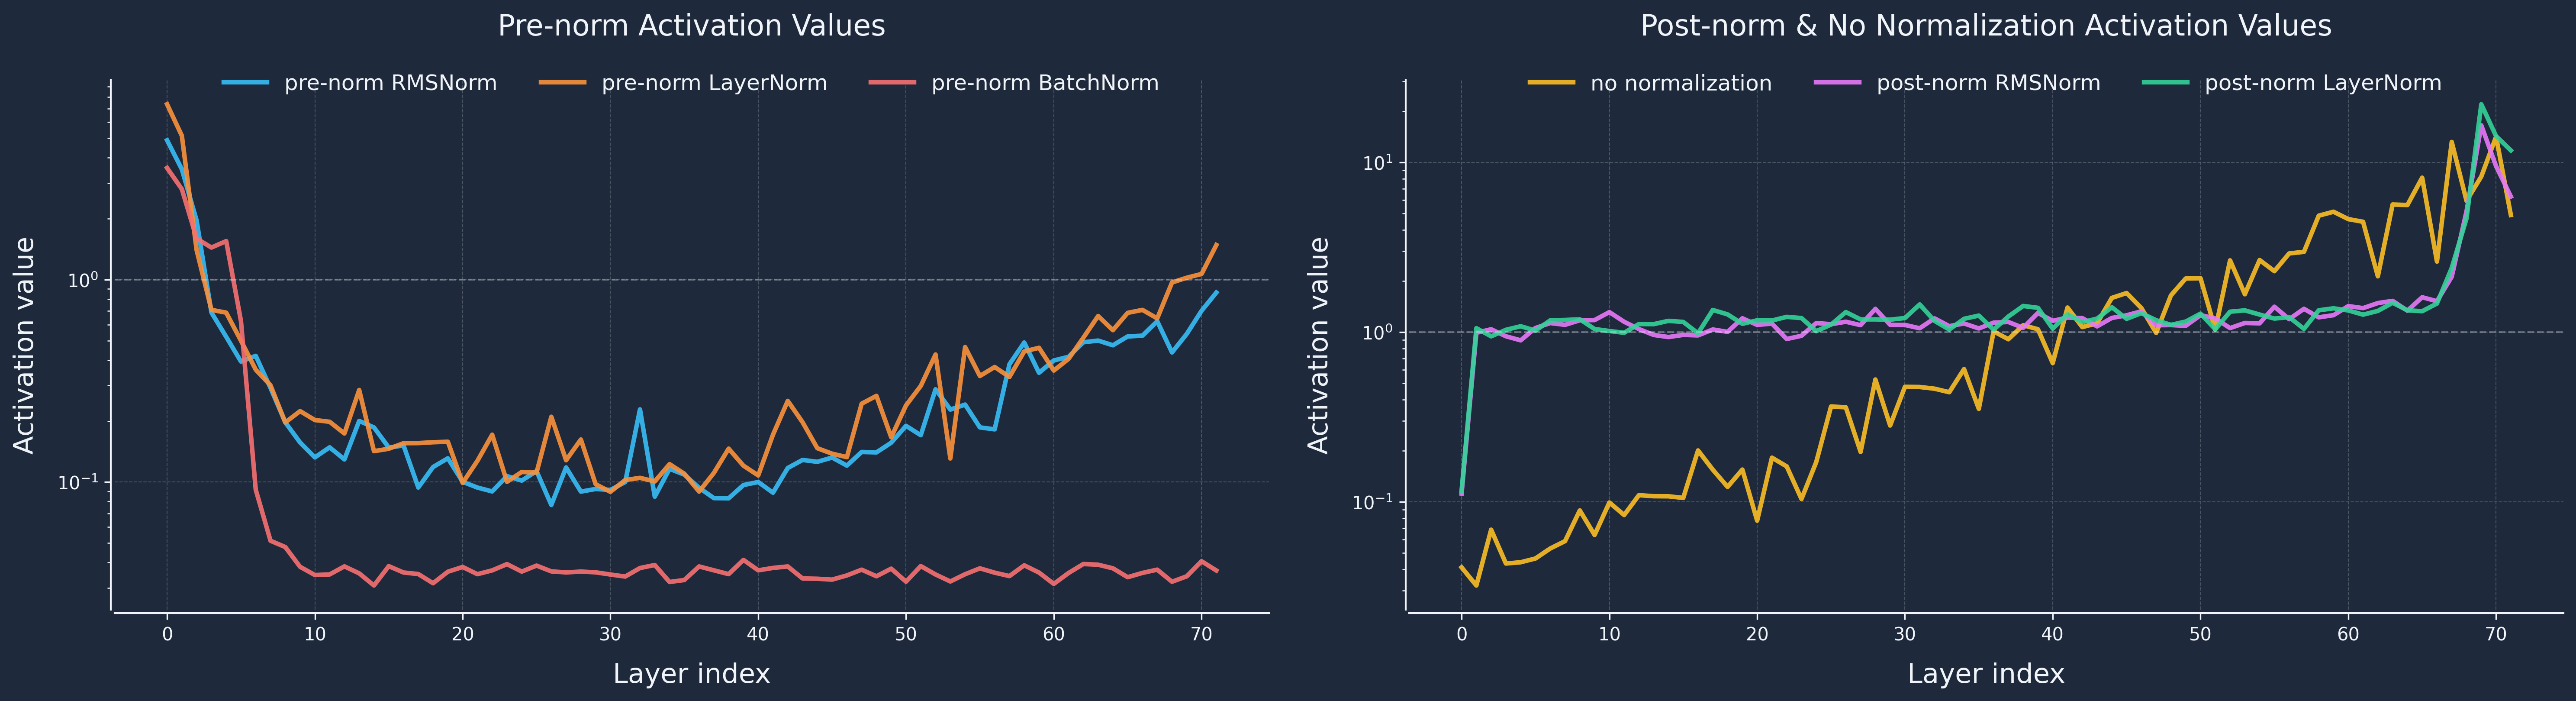

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import matplotlib.colors as mcolors
import torch

# Prefer the deployment font when available, otherwise fall back to common sans-serif fonts
font_candidates = ['Inter', 'DejaVu Sans', 'Arial', 'Helvetica', 'sans-serif']
plt.rcParams['font.family'] = font_candidates
font_path = 'fonts/Inter-Regular.ttf'
try:
    prop = fm.FontProperties(fname=font_path)
    plt.rcParams['font.family'] = prop.get_name()
except Exception:
    pass

# Set styling for all text and lines
plt.rcParams['text.color'] = '#F1F5F9'
plt.rcParams['axes.labelcolor'] = '#F1F5F9'
plt.rcParams['xtick.color'] = '#F1F5F9'
plt.rcParams['ytick.color'] = '#F1F5F9'
plt.rcParams['axes.edgecolor'] = '#F1F5F9'

# Grid styling
plt.rcParams['grid.color'] = '#5D6674'
plt.rcParams['grid.alpha'] = 0.7

# ── Signal survival per layer (post-hoc) ──
xb, yb = next(iter(test_loader))

# Create figure and axis with publication-quality settings
fig, axes = plt.subplots(1, 2, figsize=(20, 5.5), dpi=300)
fig.patch.set_facecolor('#1E293B')

# Define color mappings for specific runs
run_color_map = {
    "pre-norm BatchNorm": "#F87171", # Red hue
    "pre-norm LayerNorm": "#FB923C", # Orange hue
    "pre-norm RMSNorm": "#38BDF8",   # Blue hue
    "post-norm BatchNorm": "#A78BFA",# Purple hue
    "post-norm LayerNorm": "#34D399",# Green hue
    "post-norm RMSNorm": "#E879F9",  # Pink hue
    "no normalization": "#FBBF24"    # Yellow hue
}
fallback_colors = ["#38BDF8", "#34D399", "#FBBF24", "#F87171", "#A78BFA", "#FB923C", "#E879F9"]
line_styles = ["-","--",":","-."]

for idx, run in enumerate(all_runs):
    is_pre = "pre-norm" in run["name"]
    is_post = "post-norm" in run["name"]
    is_no = "no normalization" in run["name"]

    ax_idx = 0 if is_pre else 1
    ax = axes[ax_idx]

    model = run["model"].eval()
    if hasattr(model, "_orig_mod"):
        model = model._orig_mod

    magnitudes = []

    handles = []
    def make_hook(store):
        def hook(module, input, output):
            store.append(output.detach().abs().mean().item())
        return hook

    for block in model.layers:
        m = []
        magnitudes.append(m)
        handles.append(block.register_forward_hook(make_hook(m)))

    with torch.no_grad():
        model(xb)

    for h in handles:
        h.remove()

    layer_means = [m[0] for m in magnitudes]

    line_style = line_styles[idx % len(line_styles)] if False else '-'
    run_color = run_color_map.get(run["name"], fallback_colors[idx % len(fallback_colors)])

    ax.plot(range(len(layer_means)), layer_means,
           color=run_color,
           linewidth=2.5,
           linestyle=line_style,
           label=run["name"],
           alpha=0.9)

titles = ["Pre-norm Activation Values", "Post-norm & No Normalization Activation Values"]
for i, ax in enumerate(axes):
    ax.set_facecolor('#1E293B')
    ax.set_yscale("log")
    ax.axhline(y=1.0, color="#F1F5F9", linestyle="--", alpha=0.3, linewidth=1)

    # Customize axis labels
    ax.set_xlabel('Layer index', fontsize=15, labelpad=10, color='#F1F5F9')
    ax.set_ylabel('Activation value', fontsize=15, color='#F1F5F9', labelpad=10)
    ax.set_title(titles[i], fontsize=16, color='#F1F5F9', pad=25)

    # Add grid
    ax.grid(axis='both', alpha=0.7, color='#5D6674', linestyle='--', linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    # Add legend
    ax.legend(loc='upper center',
             bbox_to_anchor=(0.5, 1.05),
             frameon=False, fontsize=12, ncol=3)

    # Remove top and right spines for cleaner look
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1)
    ax.spines['left'].set_linewidth(1)
    ax.spines['bottom'].set_color('#F1F5F9')
    ax.spines['left'].set_color('#F1F5F9')

    # Adjust spine positions
    ax.spines['left'].set_position(('outward', 2))
    ax.spines['bottom'].set_position(('outward', 2))

# Tight layout
plt.tight_layout()

# Display the plot
plt.show()

In [ ]:
#@title (11) Save and load model
print("--- Testing Local Save & Load ---")
FILENAME = "DDN-v5.pth"
MODEL = get_model("pre-norm BatchNorm")

load_model = DNN(norm_type=nn.BatchNorm1d, is_post_norm=False).to(DEVICE)
load_model = save_load_model_local(MODEL, load_model, filename_c=FILENAME)
predicted_value = invoke_model_with_a_b_c(load_model, 11, 1, 10)

--- Testing Local Save & Load ---
model weights saved locally to: DDN-v5.pth
model weights loaded successfully into a new model instance.
Prediction for (11 * 1) % 10 = 1


In [ ]:
#@title (12) Save to Google Drive
pathname = save_to_google_drive(MODEL, FILENAME)

In [ ]:
#@title (13) Load Pretrained model from Hugging Face
print("\n--- Testing Hugging Face Download & Load ---")
hf_model = DNN(norm_type=nn.BatchNorm1d, is_post_norm=False).to(DEVICE)
hf_model = load_model_hugging_face(new_model_c=hf_model, filename_c=FILENAME)
predicted_value = invoke_model_with_a_b_c(hf_model, 13, 1, 10)

MODEL = hf_model


--- Testing Hugging Face Download & Load ---
model downloaded from HF to: /root/.cache/huggingface/hub/models--howardyang2009--llm-workshop-v1/snapshots/bf908acc95d49a5b2e02c76220fbc3b8933f1185/DDN-v5.pth
Hugging Face model loaded successfully.
Prediction for (13 * 1) % 10 = 3
